# NB-P03-01 — Probability and Statistics

Companion notebook for P03 lessons 01–06. Two themes run through it: **summary statistics can mislead**,
and **simulation is the cheapest way to check a formula**.

Every simulation uses a fixed seed, so your printed numbers will match the text.

In [1]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(seed=0)
print("ready")

ready


## 1. Centre and spread

Two columns: one symmetric, one strongly right-skewed. Compare the mean and the median in each.

In [2]:
symmetric = rng.normal(loc=68, scale=9, size=500)
skewed = rng.exponential(scale=10, size=500) + 30

rows = []
for name, values in [("symmetric", symmetric), ("skewed", skewed)]:
    s = pd.Series(values)
    rows.append({
        "column": name,
        "mean": round(float(s.mean()), 2),
        "median": round(float(s.median()), 2),
        "sd": round(float(s.std()), 2),
        "iqr": round(float(s.quantile(0.75) - s.quantile(0.25)), 2),
    })

pd.DataFrame(rows).set_index("column")

,mean,median,sd,iqr
column,,,,
symmetric,67.76,67.55,9.13,12.51
skewed,39.39,36.64,9.44,9.73


In the skewed column the mean sits well above the median: the tail pulls it. Report the median when
the distribution is asymmetric, or report both and say which question each answers.

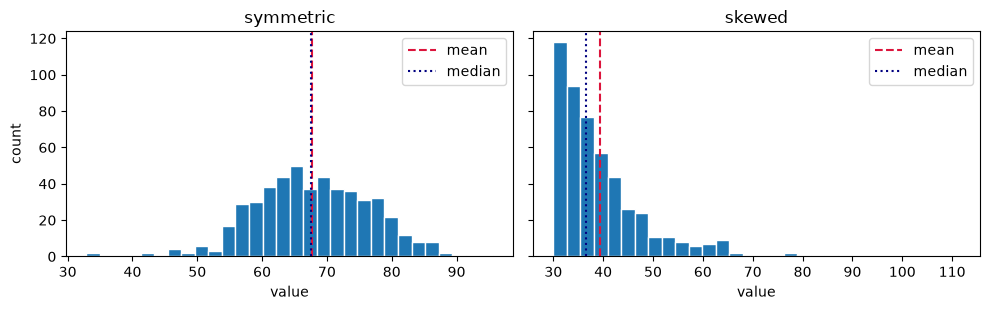

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
for ax, (name, values) in zip(axes, [("symmetric", symmetric), ("skewed", skewed)]):
    ax.hist(values, bins=30, edgecolor="white")
    ax.axvline(values.mean(), color="crimson", linestyle="--", label="mean")
    ax.axvline(np.median(values), color="navy", linestyle=":", label="median")
    ax.set_title(name)
    ax.set_xlabel("value")
    ax.legend()
axes[0].set_ylabel("count")
fig.tight_layout()
plt.show()

## 2. Expectation from a simulation

A fair die has $\mathbb{E}[X] = 3.5$ and $\operatorname{Var}(X) = 35/12 \approx 2.917$. Roll it many
times and watch the sample mean approach the theoretical value.

In [4]:
rolls = rng.integers(1, 7, size=20_000)
running = np.cumsum(rolls) / np.arange(1, rolls.size + 1)

print("first 10 means:", running[:10].round(2))
print("final mean    :", round(float(running[-1]), 4), "theory: 3.5")
print("sample var    :", round(float(rolls.var(ddof=1)), 3), "theory:", round(35 / 12, 3))

first 10 means: [6.   3.5  3.   3.25 2.8  3.   2.71 2.88 2.78 2.9 ]
final mean    : 3.4855 theory: 3.5
sample var    : 2.93 theory: 2.917


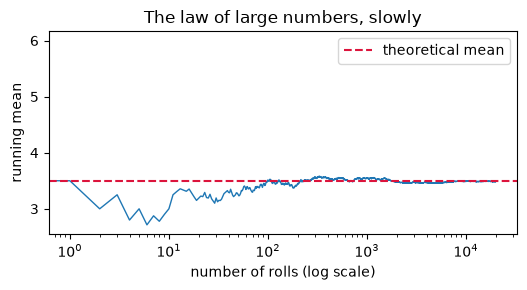

In [5]:
fig, ax = plt.subplots(figsize=(5.5, 3))
ax.plot(running, linewidth=1)
ax.axhline(3.5, color="crimson", linestyle="--", label="theoretical mean")
ax.set_xscale("log")
ax.set_xlabel("number of rolls (log scale)")
ax.set_ylabel("running mean")
ax.set_title("The law of large numbers, slowly")
ax.legend()
plt.tight_layout()
plt.show()

## 3. Conditional probability from a table

200 emails classified by spam status and whether they contain "free".

In [6]:
counts = np.array([[54, 6], [14, 126]])   # rows: spam, not spam; cols: has "free", no "free"
joint = counts / counts.sum()

p_spam = joint[0].sum()
p_free = joint[:, 0].sum()

print(f"P(spam)          = {p_spam:.3f}")
print(f"P(free)          = {p_free:.3f}")
print(f"P(spam and free) = {joint[0, 0]:.3f}")
print(f"P(spam | free)   = {joint[0, 0] / p_free:.3f}")
print(f"P(free | spam)   = {joint[0, 0] / p_spam:.3f}")
print(f"independent?      {np.isclose(joint[0, 0], p_spam * p_free)}")
print(f"P(spam or free)  = {p_spam + p_free - joint[0, 0]:.3f}")

P(spam)          = 0.300
P(free)          = 0.340
P(spam and free) = 0.270
P(spam | free)   = 0.794
P(free | spam)   = 0.900
independent?      False
P(spam or free)  = 0.370


## 4. Bayes' theorem

$P(D\mid +) = \dfrac{P(+\mid D)P(D)}{P(+\mid D)P(D) + P(+\mid D^c)P(D^c)}$. The **base rate**
$P(D)$ is the term everyone forgets, and it dominates the answer.

In [7]:
def posterior(prior, sensitivity, false_positive):
    """P(disease | positive test)."""
    evidence = sensitivity * prior + false_positive * (1 - prior)
    return sensitivity * prior / evidence


print("prevalence 1%, sensitivity 99%, false positive 5%:")
print("  P(disease | positive) =", round(posterior(0.01, 0.99, 0.05), 4))

print("\nprevalence sweep:")
for p in (0.001, 0.01, 0.05, 0.20, 0.50):
    print(f"  prior {p:>6.1%} -> posterior {posterior(p, 0.99, 0.05):.3f}")

print("\nrepeated independent positives, prior 1%:")
p = 0.01
for i in range(3):
    p = posterior(p, 0.99, 0.05)
    print(f"  after test {i + 1}: {p:.3f}")

prevalence 1%, sensitivity 99%, false positive 5%:
  P(disease | positive) = 0.1667

prevalence sweep:
  prior   0.1% -> posterior 0.019
  prior   1.0% -> posterior 0.167
  prior   5.0% -> posterior 0.510
  prior  20.0% -> posterior 0.832
  prior  50.0% -> posterior 0.952

repeated independent positives, prior 1%:
  after test 1: 0.167
  after test 2: 0.798
  after test 3: 0.987


## 5. The binomial distribution

$P(X = k) = \binom{n}{k}p^k(1-p)^{n-k}$, with $\mathbb{E}[X] = np$.

P(X = 3) = 0.2668, theory mean 3.0, var 2.10
simulated mean/var: 3.006 2.103


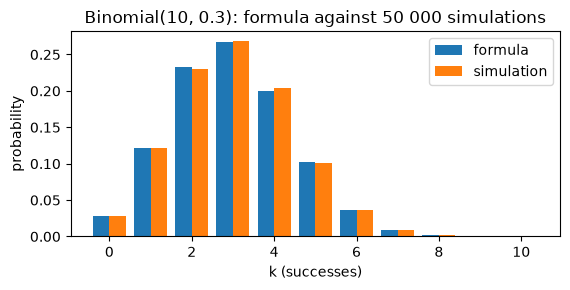

In [8]:
n, p, k = 10, 0.3, 3
exact = math.comb(n, k) * p**k * (1 - p) ** (n - k)
print(f"P(X = {k}) = {exact:.4f}, theory mean {n * p}, var {n * p * (1 - p):.2f}")

draws = rng.binomial(n, p, size=50_000)
print("simulated mean/var:", round(float(draws.mean()), 3), round(float(draws.var(ddof=1)), 3))

values = np.arange(0, n + 1)
pmf = [math.comb(n, i) * p**i * (1 - p) ** (n - i) for i in values]
empirical = np.bincount(draws, minlength=n + 1) / draws.size

fig, ax = plt.subplots(figsize=(5.8, 3))
ax.bar(values - 0.2, pmf, width=0.4, label="formula")
ax.bar(values + 0.2, empirical, width=0.4, label="simulation")
ax.set_xlabel("k (successes)")
ax.set_ylabel("probability")
ax.set_title("Binomial(10, 0.3): formula against 50 000 simulations")
ax.legend()
plt.tight_layout()
plt.show()

## 6. The normal distribution

Standardise with $z = (x-\mu)/\sigma$ and use $\Phi$, computed here from `math.erf` so no extra
library is needed.

In [9]:
def phi(z):
    """Standard normal CDF."""
    return 0.5 * (1 + math.erf(z / math.sqrt(2)))


mu, sigma = 68, 9
print("P(score <= 70) =", round(phi((70 - mu) / sigma), 4))
print("P(59 <= score <= 77) =", round(phi(1) - phi(-1), 4), "(empirical rule: ~0.68)")
print("P(50 <= score <= 86) =", round(phi(2) - phi(-2), 4), "(empirical rule: ~0.95)")

scores = rng.normal(mu, sigma, size=20_000)
for k in (1, 2, 3):
    share = float(np.mean(np.abs(scores - mu) <= k * sigma))
    print(f"within {k} sigma: {share:.3f} (rule of thumb: {[0.68, 0.95, 0.997][k - 1]})")

P(score <= 70) = 0.5879
P(59 <= score <= 77) = 0.6827 (empirical rule: ~0.68)
P(50 <= score <= 86) = 0.9545 (empirical rule: ~0.95)
within 1 sigma: 0.688 (rule of thumb: 0.68)
within 2 sigma: 0.955 (rule of thumb: 0.95)
within 3 sigma: 0.997 (rule of thumb: 0.997)


## 7. Sampling distributions and the central limit theorem

Take 2 000 samples of size 40 from a strongly skewed distribution. The **means** are approximately
normal with standard error $\sigma/\sqrt{n}$ — even though the data are not normal.

In [10]:
means = rng.exponential(scale=2.0, size=(2000, 40)).mean(axis=1)
print("mean of means :", round(float(means.mean()), 3), "(theory 2.0)")
print("observed SE   :", round(float(means.std(ddof=1)), 3))
print("predicted SE  :", round(2.0 / math.sqrt(40), 3))

mean of means : 1.991 (theory 2.0)
observed SE   : 0.325
predicted SE  : 0.316


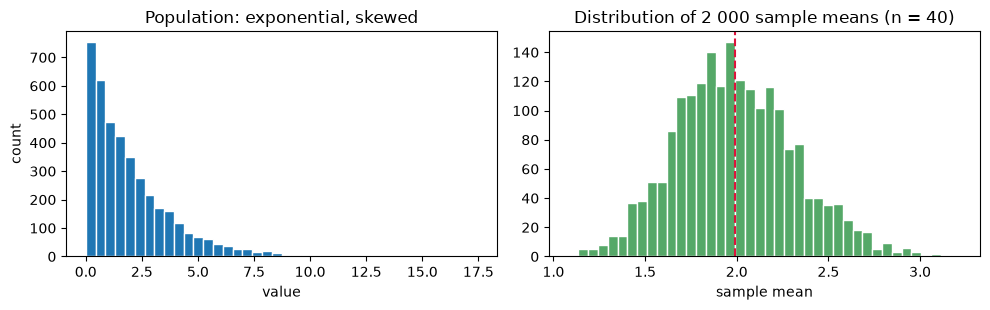

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].hist(rng.exponential(scale=2.0, size=4000), bins=40, edgecolor="white")
axes[0].set_title("Population: exponential, skewed")
axes[0].set_xlabel("value")
axes[0].set_ylabel("count")

axes[1].hist(means, bins=40, edgecolor="white", color="#55a868")
axes[1].axvline(means.mean(), color="crimson", linestyle="--")
axes[1].set_title("Distribution of 2 000 sample means (n = 40)")
axes[1].set_xlabel("sample mean")
fig.tight_layout()
plt.show()

## 8. Covariance, correlation, and what $r$ misses

$r$ measures **linear** association. The second column below is an exact function of the first, and its
correlation is close to zero.

In [12]:
x = rng.uniform(-3, 3, size=400)
table = pd.DataFrame({
    "x": x,
    "linear": 2 * x + rng.normal(scale=0.4, size=400),
    "quadratic": x**2 + rng.normal(scale=0.4, size=400),
})
print(table.corr().round(3).to_string())
print("\ncovariance matrix:\n", np.cov(table["x"], table["linear"]).round(3))

               x  linear  quadratic
x          1.000   0.994      0.029
linear     0.994   1.000      0.023
quadratic  0.029   0.023      1.000

covariance matrix:
 [[ 3.218  6.418]
 [ 6.418 12.944]]


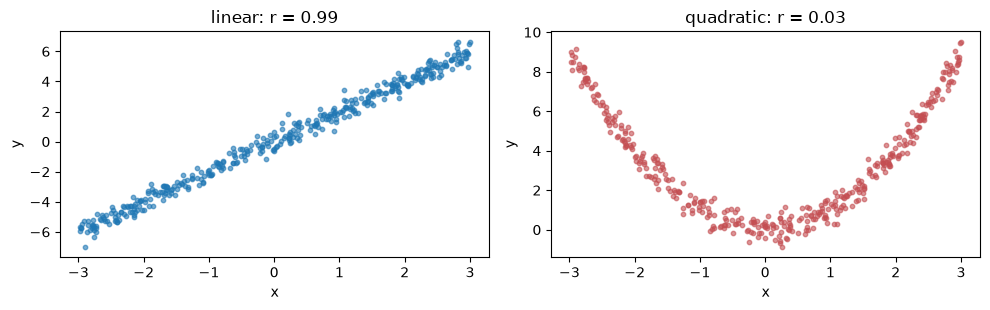

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].scatter(table["x"], table["linear"], s=10, alpha=0.6)
axes[0].set_title(f"linear: r = {table['x'].corr(table['linear']):.2f}")
axes[1].scatter(table["x"], table["quadratic"], s=10, alpha=0.6, color="#c44e52")
axes[1].set_title(f"quadratic: r = {table['x'].corr(table['quadratic']):.2f}")
for ax in axes:
    ax.set_xlabel("x")
    ax.set_ylabel("y")
fig.tight_layout()
plt.show()

## 9. A paired permutation test

Eight students measured before and after a workshop. Under the null, each difference is equally likely to
be positive or negative, so flipping random signs generates the null distribution directly.

In [14]:
before = np.array([62, 58, 71, 65, 60, 67, 55, 70])
after = np.array([68, 61, 74, 66, 66, 70, 58, 73])
diff = after - before
observed = diff.mean()

diff_rng = np.random.default_rng(seed=1)
count = 0
for _ in range(10_000):
    signs = diff_rng.choice([-1, 1], size=diff.size)
    if abs((signs * diff).mean()) >= abs(observed):
        count += 1

t_stat = observed / (diff.std(ddof=1) / math.sqrt(diff.size))
print("mean gain:", round(float(observed), 2))
print("t statistic:", round(float(t_stat), 3), "df =", diff.size - 1)
print("Cohen's d:", round(float(observed / diff.std(ddof=1)), 2))
print("permutation p:", round(count / 10_000, 4))

mean gain: 3.5
t statistic: 5.857 df = 7
Cohen's d: 2.07
permutation p: 0.0081


## 10. Exercises

1. Generate 1 000 draws from a normal(50, 5) and report the fraction within one standard deviation.
2. A test has sensitivity 95% and a false-positive rate 2%, with prevalence 0.5%. Compute the posterior
   for a positive result. Is the test useful for screening?
3. Simulate 10 000 samples of size 5 from an exponential distribution and compare the standard deviation
   of the means with $\sigma/\sqrt{5}$. Is the normal approximation good at this sample size?

In [15]:
# 1
draws = rng.normal(50, 5, size=1000)
print(round(float(np.mean(np.abs(draws - 50) <= 5)), 3))

0.669


In [16]:
# 2
print(round(posterior(0.005, 0.95, 0.02), 4))

0.1927


In [17]:
# 3
small = rng.exponential(scale=2.0, size=(10_000, 5)).mean(axis=1)
print("observed SE:", round(float(small.std(ddof=1)), 3), "predicted:", round(2 / math.sqrt(5), 3))
print("skew of means:", round(float(pd.Series(small).skew()), 3))

observed SE: 0.895 predicted: 0.894
skew of means: 0.811


## 11. Check yourself

1. Why can a 99% sensitive test still give a 17% posterior?
2. What is the difference between the standard deviation and the standard error?
3. Why does the sample variance divide by $n-1$?
4. Why is "p = 0.03" not "a 3% chance the null is true"?

Next: [P04 — Data Preparation](../../P04-data-preparation-and-visualization/README.md).